<a href="https://colab.research.google.com/github/para5ol/ML_course_homework/blob/main/AI_vs_Human_Academic_Writing_Dataset_Homework.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [61]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
%matplotlib inline

<h2>Чтение данных и постановка задачи<h2>

In [62]:
data = pd.read_csv('/content/ai_writing_detection_dataset.csv')

AI vs Human Academic Writing Dataset - синтетический датасет из 10200 записей характеристик различных текстов. Поставленная задача - задача бинарной классификации - определить участвовал ли ИИ при написании этого текста.

Краткая характеристика датасета:

1) Несбалансированные классы - примерно 85.5% тестов написаны людьми(class 0), остальные 14.5% за авторством ИИ(class 1)

2) Есть выбросы, например, большое количество грамматических ошибок или невероятно большое время редактирования

3) В датасете есть дубликаты - примерно 2% записей

4) В датасете есть 19 категориальных и числовых признаков

In [63]:
type(data)

pandas.core.frame.DataFrame

In [64]:
data

,Student_ID,Submission_Type,Academic_Level,Primary_Language,Word_Count,Average_Sentence_Length,Grammar_Errors,Vocabulary_Richness,Passive_Voice_Ratio,Reading_Level,Editing_Time,Revision_Count,Typing_Speed,Plagiarism_Score,Citation_Count,Punctuation_Density,Sentence_Complexity,Font_Family,Submission_Hour,Is_AI_Assisted
0,16959e76,Lab_Report,Postgraduate,Native,1552,16.90,8,0.62,0.11,11.85,129.05,16.0,24.70,3.02,0.0,0.08,2.01,Arial,18,0
1,0a304e7f,Research_Paper,Undergraduate,Native,950,16.71,5,0.47,0.31,10.34,236.60,23.0,38.84,1.71,15.0,0.07,1.72,Helvetica,15,0
2,6e629f9f,Essay,Undergraduate,Non_Native,1103,22.10,1,0.76,0.38,14.35,4.72,4.0,0.00,0.41,0.0,0.08,2.35,Arial,17,1
3,16334d32,Essay,Postgraduate,Native,1189,20.00,7,0.61,0.26,10.93,NaN,24.0,41.92,3.06,5.0,0.05,1.68,Times New Roman,5,0
4,54d8e254,Essay,Undergraduate,Native,1035,22.67,2,0.80,0.33,15.30,16.82,2.0,0.00,2.78,1.0,0.09,2.90,Helvetica,8,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
10195,789f9003,Research_Paper,Undergraduate,Non_Native,1216,10.30,6,0.48,0.21,8.07,121.03,28.0,45.40,2.65,20.0,0.05,1.64,Arial,18,0
10196,d74b373f,Essay,Postgraduate,Native,1062,10.60,6,0.41,0.32,15.08,142.36,25.0,37.91,NaN,4.0,0.06,1.66,Arial,15,0
10197,309522b4,Essay,High_School,Non_Native,950,18.67,5,0.63,0.24,12.60,180.62,23.0,53.38,9.64,8.0,0.00,1.98,Helvetica,20,0
10198,01b91f92,Literature_Review,Undergraduate,Native,1012,20.73,6,0.52,0.05,10.16,146.61,28.0,69.99,NaN,28.0,0.06,1.10,Times New Roman,23,0


In [65]:
print(data)

      Student_ID    Submission_Type Academic_Level Primary_Language  \
0       16959e76         Lab_Report   Postgraduate           Native   
1       0a304e7f     Research_Paper  Undergraduate           Native   
2       6e629f9f              Essay  Undergraduate       Non_Native   
3       16334d32              Essay   Postgraduate           Native   
4       54d8e254              Essay  Undergraduate           Native   
...          ...                ...            ...              ...   
10195   789f9003     Research_Paper  Undergraduate       Non_Native   
10196   d74b373f              Essay   Postgraduate           Native   
10197   309522b4              Essay    High_School       Non_Native   
10198   01b91f92  Literature_Review  Undergraduate           Native   
10199   4afcd3b1     Research_Paper  Undergraduate           Native   

       Word_Count  Average_Sentence_Length  Grammar_Errors  \
0            1552                    16.90               8   
1             950      

In [66]:
data.head()

,Student_ID,Submission_Type,Academic_Level,Primary_Language,Word_Count,Average_Sentence_Length,Grammar_Errors,Vocabulary_Richness,Passive_Voice_Ratio,Reading_Level,Editing_Time,Revision_Count,Typing_Speed,Plagiarism_Score,Citation_Count,Punctuation_Density,Sentence_Complexity,Font_Family,Submission_Hour,Is_AI_Assisted
0,16959e76,Lab_Report,Postgraduate,Native,1552,16.90,8,0.62,0.11,11.85,129.05,16.0,24.70,3.02,0.0,0.08,2.01,Arial,18,0
1,0a304e7f,Research_Paper,Undergraduate,Native,950,16.71,5,0.47,0.31,10.34,236.60,23.0,38.84,1.71,15.0,0.07,1.72,Helvetica,15,0
2,6e629f9f,Essay,Undergraduate,Non_Native,1103,22.10,1,0.76,0.38,14.35,4.72,4.0,0.00,0.41,0.0,0.08,2.35,Arial,17,1
3,16334d32,Essay,Postgraduate,Native,1189,20.00,7,0.61,0.26,10.93,NaN,24.0,41.92,3.06,5.0,0.05,1.68,Times New Roman,5,0
4,54d8e254,Essay,Undergraduate,Native,1035,22.67,2,0.80,0.33,15.30,16.82,2.0,0.00,2.78,1.0,0.09,2.90,Helvetica,8,1


In [67]:
data.tail()

,Student_ID,Submission_Type,Academic_Level,Primary_Language,Word_Count,Average_Sentence_Length,Grammar_Errors,Vocabulary_Richness,Passive_Voice_Ratio,Reading_Level,Editing_Time,Revision_Count,Typing_Speed,Plagiarism_Score,Citation_Count,Punctuation_Density,Sentence_Complexity,Font_Family,Submission_Hour,Is_AI_Assisted
10195,789f9003,Research_Paper,Undergraduate,Non_Native,1216,10.30,6,0.48,0.21,8.07,121.03,28.0,45.40,2.65,20.0,0.05,1.64,Arial,18,0
10196,d74b373f,Essay,Postgraduate,Native,1062,10.60,6,0.41,0.32,15.08,142.36,25.0,37.91,NaN,4.0,0.06,1.66,Arial,15,0
10197,309522b4,Essay,High_School,Non_Native,950,18.67,5,0.63,0.24,12.60,180.62,23.0,53.38,9.64,8.0,0.00,1.98,Helvetica,20,0
10198,01b91f92,Literature_Review,Undergraduate,Native,1012,20.73,6,0.52,0.05,10.16,146.61,28.0,69.99,NaN,28.0,0.06,1.10,Times New Roman,23,0
10199,4afcd3b1,Research_Paper,Undergraduate,Native,1590,14.37,7,0.75,0.13,6.75,259.88,NaN,18.06,NaN,21.0,0.08,2.10,Arial,22,0


<h2>В датасете есть 19 категориальных и числовых признаков(не считая Student_ID):<h2>

<h3>Категориальные<h3>

Submission_Type - тип текста(исследование, эссе и т.д.)

Academic_Level - Уровень образования

Primary_Language - Является ли язык родным или нет

Font_Family - используемый шрифт

<h3>Числовые<h3>

Word_Count - Число слов в тексте

Average_Sentence_Length - Средняя длина предложения

Grammar_Errors - Количество грамматических ошибок

Vocabulary_Richness - Богатство словарного запаса

Passive_Voice_Ratio - Доля используемого в тексте пассивного залога

Reading_Level - уровень чтения

Editing_Time - Время редактирования

Revision_Count - Количество правок

Typing_Speed - Скорость печати

Plagiarism_Score - Оценка на плагиат

Citations_Count - Число цитат

Punctuation_Density - Частота использования
знаков пунктуации

Sentence_Complexity - Сложность предложения

Submission_Hour - Время отправки текста

Is_AI_Assisted - Помогал ли ИИ при составлении текста, именно это мы и хотим научиться предсказывать

In [68]:
print(data.shape)
print(data.columns)

(10200, 20)
Index(['Student_ID', 'Submission_Type', 'Academic_Level', 'Primary_Language',
       'Word_Count', 'Average_Sentence_Length', 'Grammar_Errors',
       'Vocabulary_Richness', 'Passive_Voice_Ratio', 'Reading_Level',
       'Editing_Time', 'Revision_Count', 'Typing_Speed', 'Plagiarism_Score',
       'Citation_Count', 'Punctuation_Density', 'Sentence_Complexity',
       'Font_Family', 'Submission_Hour', 'Is_AI_Assisted'],
      dtype='object')


<h3>Разберемся с дубликатами<h3>

В описании датасета указано, что в нем присутствуют дубликаты, поэтому посмотрим их количество и уберем.

In [69]:
data.duplicated().sum()

np.int64(200)

In [70]:
data = data.drop_duplicates()
print(data.shape)

(10000, 20)


In [71]:
data.index

Index([    0,     1,     2,     3,     4,     5,     6,     7,     8,     9,
       ...
       10190, 10191, 10192, 10193, 10194, 10195, 10196, 10197, 10198, 10199],
      dtype='int64', length=10000)

In [72]:
data['Passive_Voice_Ratio']

,Passive_Voice_Ratio
0,0.11
1,0.31
2,0.38
3,0.26
4,0.33
...,...
10195,0.21
10196,0.32
10197,0.24
10198,0.05


In [73]:
data.describe()

,Word_Count,Average_Sentence_Length,Grammar_Errors,Vocabulary_Richness,Passive_Voice_Ratio,Reading_Level,Editing_Time,Revision_Count,Typing_Speed,Plagiarism_Score,Citation_Count,Punctuation_Density,Sentence_Complexity,Submission_Hour,Is_AI_Assisted
count,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,9133.000000,8515.000000,9016.000000,9200.000000,9028.000000,10000.000000,10000.000000,10000.000000,10000.000000
mean,1200.971400,16.926677,7.335300,0.622310,0.204663,11.478234,161.914641,21.572402,163.669819,7.165453,9.419140,0.053976,1.931766,11.558300,0.144800
std,394.951282,4.639200,5.057295,0.098771,0.096760,2.538285,110.377274,9.342642,354.175040,7.657642,9.094972,0.021659,0.575410,6.940923,0.351917
min,300.000000,5.000000,0.000000,0.290000,0.000000,5.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000
25%,925.000000,13.610000,5.000000,0.550000,0.140000,9.700000,112.000000,19.000000,34.747500,1.850000,2.000000,0.040000,1.480000,5.000000,0.000000
50%,1196.000000,17.070000,7.000000,0.620000,0.200000,11.570000,167.880000,24.000000,46.470000,4.640000,5.000000,0.050000,1.930000,12.000000,0.000000
75%,1470.000000,20.622500,9.000000,0.700000,0.270000,13.420000,213.740000,27.000000,59.282500,9.855000,17.000000,0.070000,2.360000,18.000000,0.000000
max,2588.000000,33.620000,78.000000,0.900000,0.520000,20.000000,1493.400000,45.000000,1200.000000,72.330000,36.000000,0.130000,4.060000,23.000000,1.000000


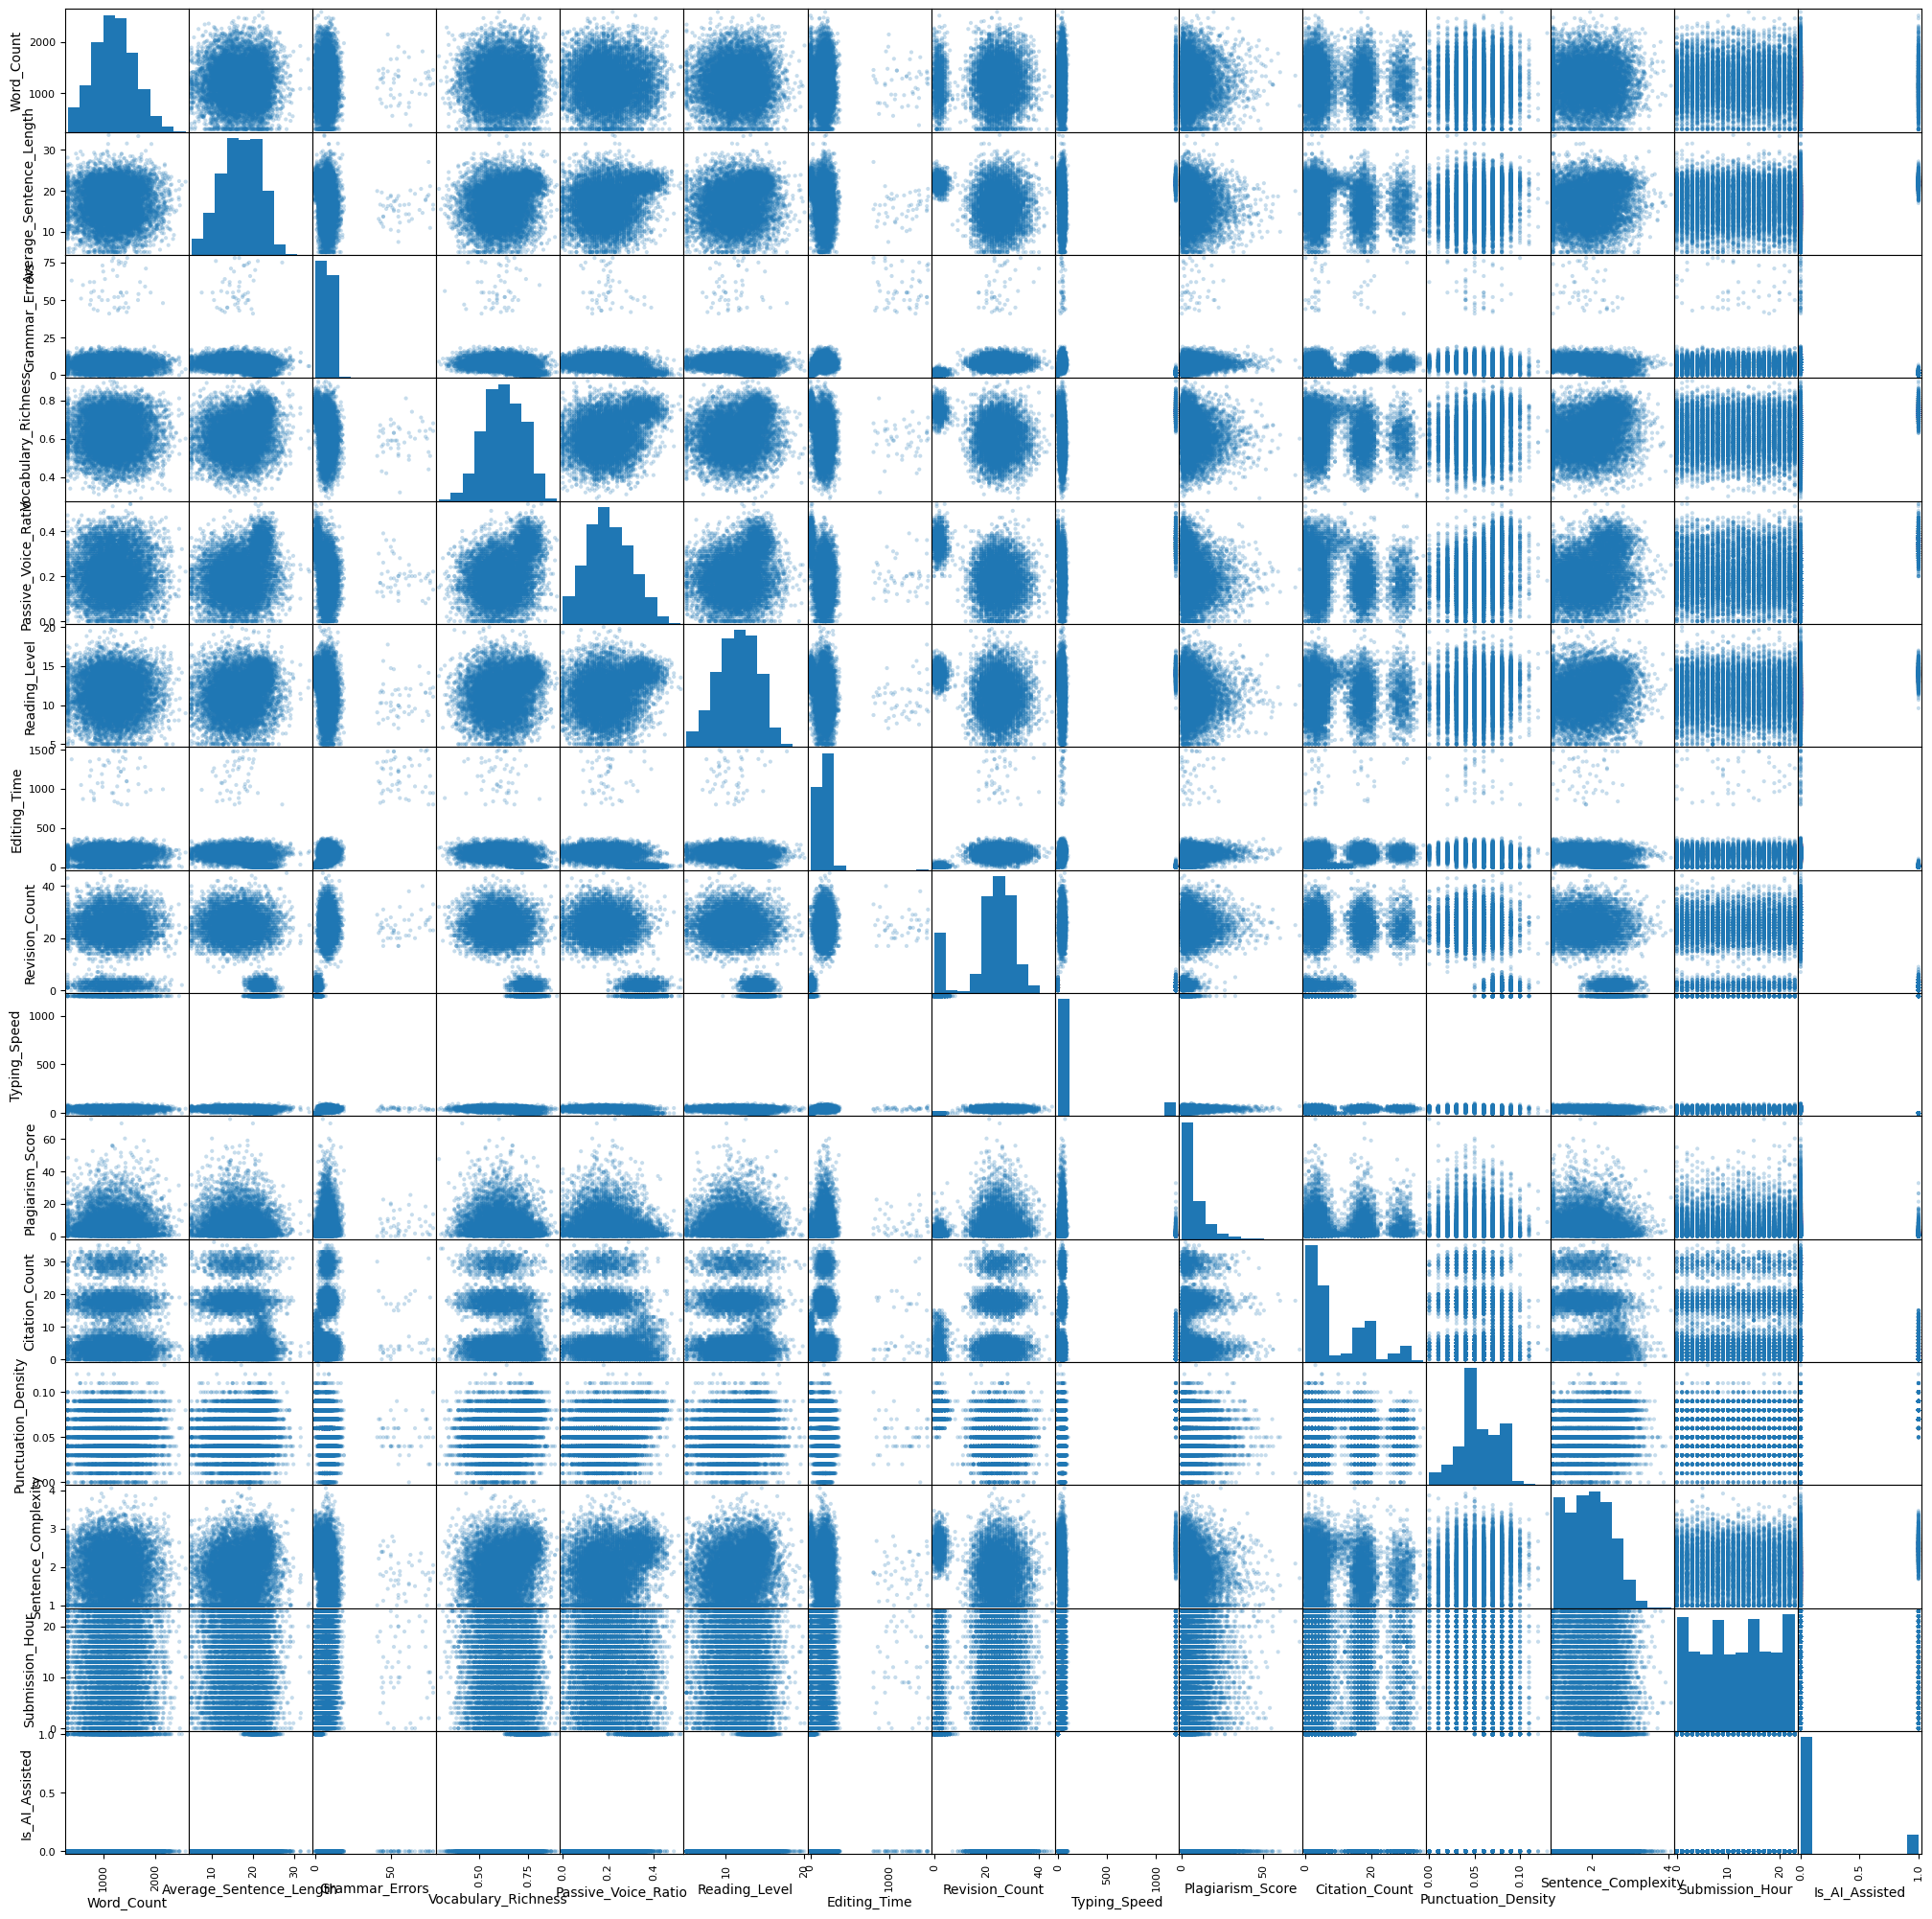

In [74]:
from pandas.plotting import scatter_matrix
scatter_matrix(data, alpha = .25, figsize = (25, 25))
pass

Едва ли на прошлой матрице что-то видно, поэтому просмотрим матрицу рассеивания для наиболее полезных данных.

array([[<Axes: xlabel='Word_Count', ylabel='Word_Count'>,
        <Axes: xlabel='Average_Sentence_Length', ylabel='Word_Count'>,
        <Axes: xlabel='Grammar_Errors', ylabel='Word_Count'>,
        <Axes: xlabel='Vocabulary_Richness', ylabel='Word_Count'>,
        <Axes: xlabel='Passive_Voice_Ratio', ylabel='Word_Count'>,
        <Axes: xlabel='Sentence_Complexity', ylabel='Word_Count'>,
        <Axes: xlabel='Is_AI_Assisted', ylabel='Word_Count'>],
       [<Axes: xlabel='Word_Count', ylabel='Average_Sentence_Length'>,
        <Axes: xlabel='Average_Sentence_Length', ylabel='Average_Sentence_Length'>,
        <Axes: xlabel='Grammar_Errors', ylabel='Average_Sentence_Length'>,
        <Axes: xlabel='Vocabulary_Richness', ylabel='Average_Sentence_Length'>,
        <Axes: xlabel='Passive_Voice_Ratio', ylabel='Average_Sentence_Length'>,
        <Axes: xlabel='Sentence_Complexity', ylabel='Average_Sentence_Length'>,
        <Axes: xlabel='Is_AI_Assisted', ylabel='Average_Sentence_Length'>],

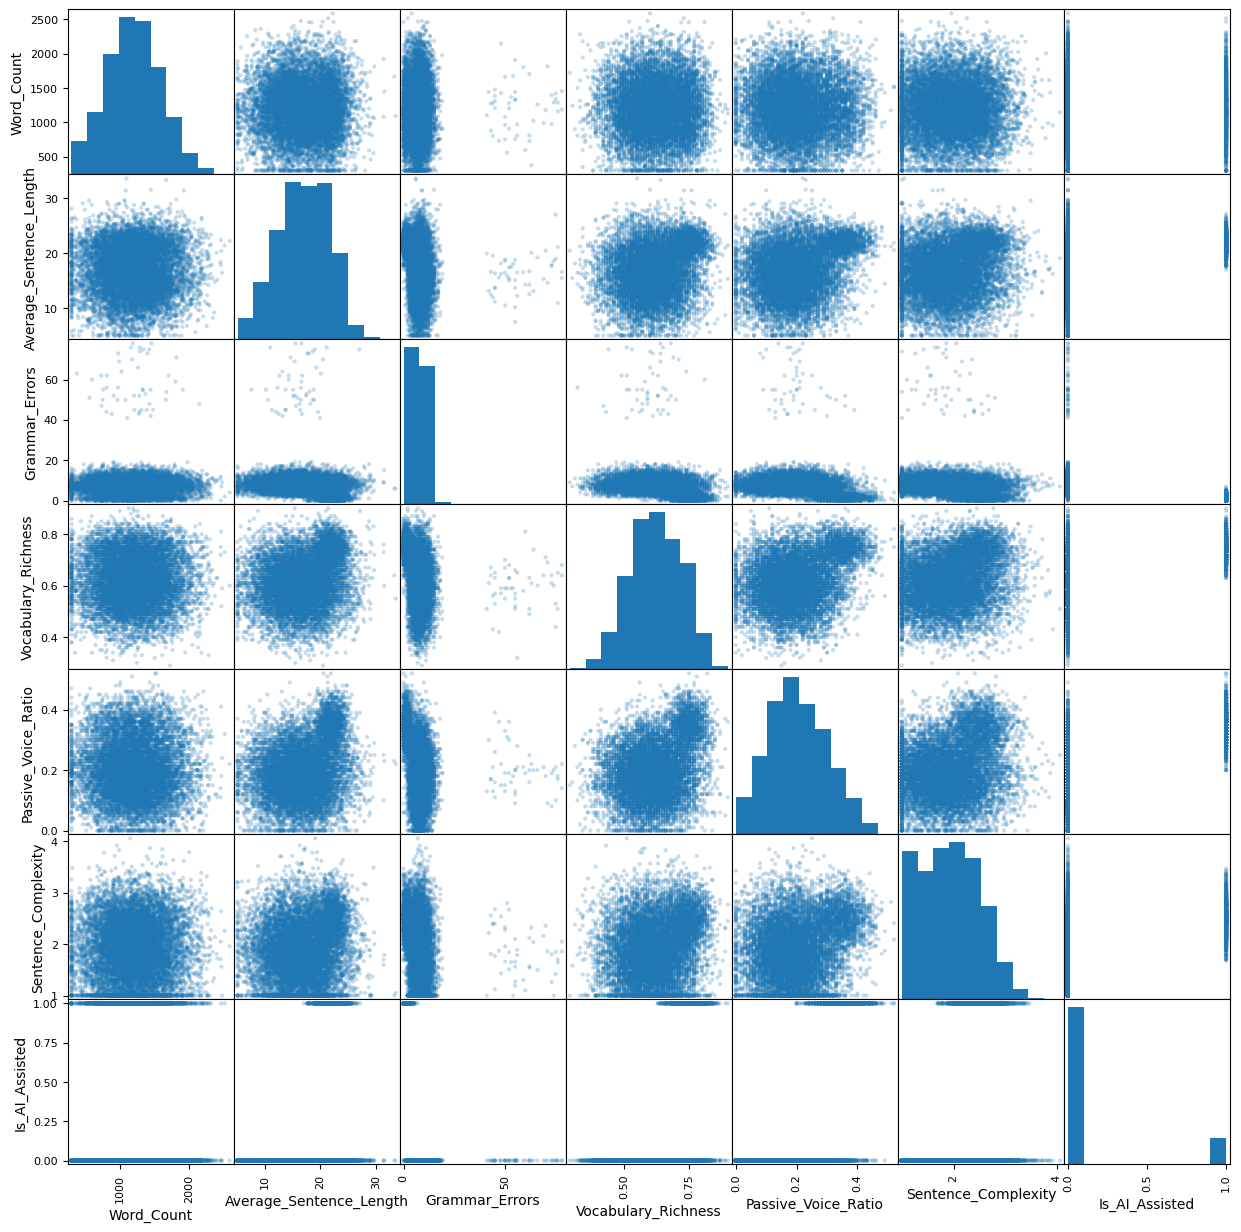

In [75]:
important_data = ['Word_Count', 'Average_Sentence_Length', 'Grammar_Errors','Vocabulary_Richness','Passive_Voice_Ratio', 'Sentence_Complexity', 'Is_AI_Assisted']
scatter_matrix(data[important_data], alpha = .25, figsize = (15, 15))

Нетрудно заметить большое количество выбросов для признака Grammar_Errors

In [76]:
numeric_data = data.select_dtypes(include=['number'])
numeric_data.corr()

,Word_Count,Average_Sentence_Length,Grammar_Errors,Vocabulary_Richness,Passive_Voice_Ratio,Reading_Level,Editing_Time,Revision_Count,Typing_Speed,Plagiarism_Score,Citation_Count,Punctuation_Density,Sentence_Complexity,Submission_Hour,Is_AI_Assisted
Word_Count,1.000000,0.004342,0.008101,0.000978,-0.011800,0.008381,0.010463,0.015081,-0.015510,0.008656,-0.003374,-0.004906,0.006463,-0.000489,-0.006049
Average_Sentence_Length,0.004342,1.000000,-0.209508,0.242100,0.282035,0.197569,-0.230367,-0.388621,0.363224,-0.107555,-0.127240,0.217850,0.173719,-0.010473,0.447226
Grammar_Errors,0.008101,-0.209508,1.000000,-0.255927,-0.291638,-0.203418,0.713874,0.408027,-0.385461,0.113358,0.102999,-0.226752,-0.202943,0.008376,-0.476549
Vocabulary_Richness,0.000978,0.242100,-0.255927,1.000000,0.333997,0.213579,-0.288153,-0.465791,0.425952,-0.127614,-0.141521,0.241762,0.217280,0.006326,0.526550
Passive_Voice_Ratio,-0.011800,0.282035,-0.291638,0.333997,1.000000,0.252442,-0.323241,-0.537683,0.507902,-0.136242,-0.154628,0.298892,0.250167,-0.014579,0.618588
Reading_Level,0.008381,0.197569,-0.203418,0.213579,0.252442,1.000000,-0.224929,-0.366847,0.336496,-0.084810,-0.086370,0.213757,0.181460,-0.019695,0.414200
Editing_Time,0.010463,-0.230367,0.713874,-0.288153,-0.323241,-0.224929,1.000000,0.461582,-0.439772,0.127863,0.125402,-0.256554,-0.225707,0.003662,-0.543226
Revision_Count,0.015081,-0.388621,0.408027,-0.465791,-0.537683,-0.366847,0.461582,1.000000,-0.707389,0.204231,0.213121,-0.433741,-0.359768,0.009731,-0.869565
Typing_Speed,-0.015510,0.363224,-0.385461,0.425952,0.507902,0.336496,-0.439772,-0.707389,1.000000,-0.194856,-0.189347,0.398611,0.332205,-0.007699,0.811369
Plagiarism_Score,0.008656,-0.107555,0.113358,-0.127614,-0.136242,-0.084810,0.127863,0.204231,-0.194856,1.000000,0.041009,-0.121118,-0.098934,0.002285,-0.235763


На этом графике чётко видно связь между частым использованием пассивного залога и богатством словарного запаса, что, впрочем, можно было заметить еще в матрице корреляции, где есть вполне заметная положительная корреляция между двумя этими признаками.

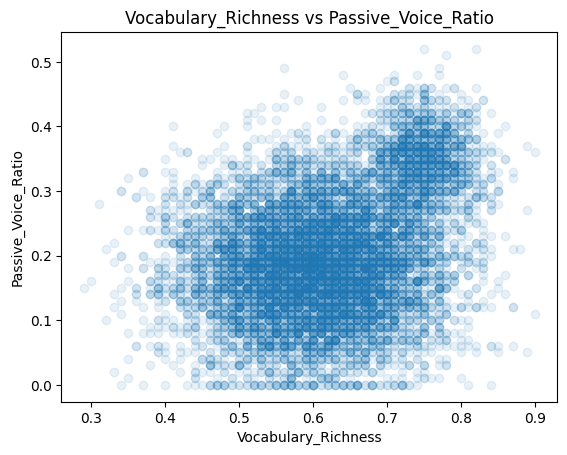

In [77]:
plt.plot(data['Vocabulary_Richness'], data['Passive_Voice_Ratio'], 'o', alpha = 0.1)
plt.xlabel('Vocabulary_Richness')
plt.ylabel('Passive_Voice_Ratio')
plt.title('Vocabulary_Richness vs Passive_Voice_Ratio')
pass

Следующий график показывает вполне очевидную вещь - ИИ чаще использует пассивный залог и также он обладает большим словарным запасом, впрочем, здесь различия слишком явные, а в реальной жизни человек может написать сложный текст, используя различные грамматические и словестные конструкции, в то время как ИИ можно попросить написать текст попроще, поэтому скорее всего эти признаки стоит опустить, поскольку иначе задача будет слишком простой.

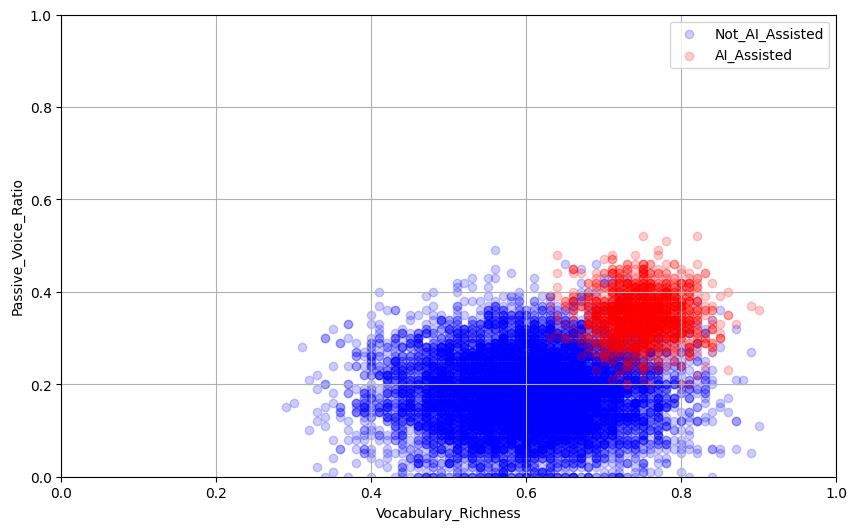

In [78]:
plt.figure(figsize = (10, 6))

plt.scatter(data[data['Is_AI_Assisted'] == 0]['Vocabulary_Richness'],
            data[data['Is_AI_Assisted'] == 0]['Passive_Voice_Ratio'],
            alpha = 0.2,
            label = 'Not_AI_Assisted',
            color = 'b')

plt.scatter(data[data['Is_AI_Assisted'] == 1]['Vocabulary_Richness'],
            data[data['Is_AI_Assisted'] == 1]['Passive_Voice_Ratio'],
            alpha = 0.2,
            label = 'AI_Assisted',
            color = 'r')

plt.xlabel('Vocabulary_Richness')
plt.xlim(0, 1)
plt.ylabel('Passive_Voice_Ratio')
plt.ylim(0, 1)
plt.legend()
plt.grid()

Следующий график с осями Editing_Time и Revision_Count показывает хоть и почти самоочевидную, но не самую приятную вещь - ИИ значительно быстрее редактирует документы и применяет гораздо меньше правок, чем люди, что может слишком сильно упростить задачу для модели, поэтому, возможно, стоит убрать эти признаки. Кроме этого, есть немало выбросов по Editing_Time, но раз уж мы не собираемся учитывать этот признак, обрабатывать их не будем.  

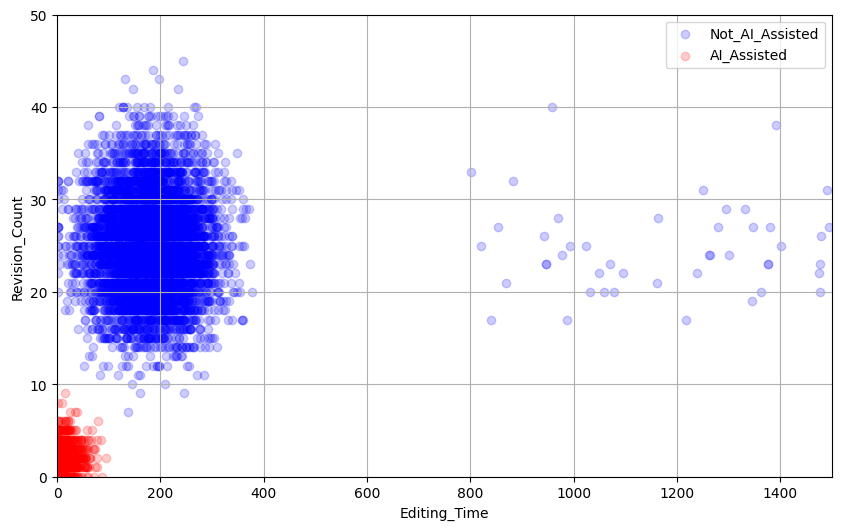

In [79]:
plt.figure(figsize = (10, 6))

plt.scatter(data[data['Is_AI_Assisted'] == 0]['Editing_Time'],
            data[data['Is_AI_Assisted'] == 0]['Revision_Count'],
            alpha = 0.2,
            label = 'Not_AI_Assisted',
            color = 'b')

plt.scatter(data[data['Is_AI_Assisted'] == 1]['Editing_Time'],
            data[data['Is_AI_Assisted'] == 1]['Revision_Count'],
            alpha = 0.2,
            label = 'AI_Assisted',
            color = 'r')

plt.xlabel('Editing_Time')
plt.xlim(0, 1500)
plt.ylabel('Revision_Count')
plt.ylim(0, 50)
plt.legend()
plt.grid()

Аналогично для Typing_Speed и Grammar_Errors и если количество ошибок реально зафиксировать, то оценить скорость печати в реальных условиях будет непростой задачей. Поэтому, учитывая такое распределение данных, эти признаки тоже можно опустить.

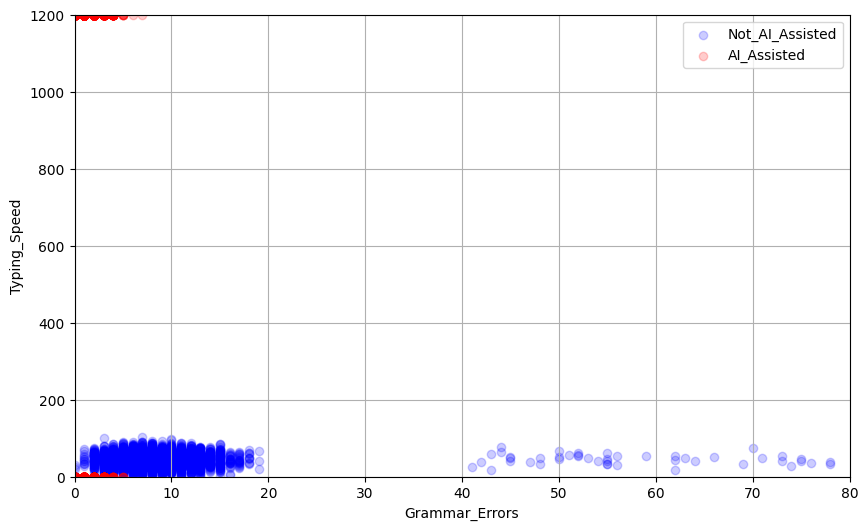

In [80]:
plt.figure(figsize = (10, 6))

plt.scatter(data[data['Is_AI_Assisted'] == 0]['Grammar_Errors'],
            data[data['Is_AI_Assisted'] == 0]['Typing_Speed'],
            alpha = 0.2,
            label = 'Not_AI_Assisted',
            color = 'b')

plt.scatter(data[data['Is_AI_Assisted'] == 1]['Grammar_Errors'],
            data[data['Is_AI_Assisted'] == 1]['Typing_Speed'],
            alpha = 0.2,
            label = 'AI_Assisted',
            color = 'r')

plt.xlabel('Grammar_Errors')
plt.xlim(0, 80)
plt.ylabel('Typing_Speed')
plt.ylim(0, 1200)
plt.legend()
plt.grid()

In [81]:
data.describe(include = 'all')

,Student_ID,Submission_Type,Academic_Level,Primary_Language,Word_Count,Average_Sentence_Length,Grammar_Errors,Vocabulary_Richness,Passive_Voice_Ratio,Reading_Level,Editing_Time,Revision_Count,Typing_Speed,Plagiarism_Score,Citation_Count,Punctuation_Density,Sentence_Complexity,Font_Family,Submission_Hour,Is_AI_Assisted
count,10000,10000,10000,10000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,9133.000000,8515.000000,9016.000000,9200.000000,9028.000000,10000.000000,10000.000000,10000,10000.000000,10000.000000
unique,10000,4,3,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,4,NaN,NaN
top,a63d23b9,Essay,Undergraduate,Native,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Calibri,NaN,NaN
freq,1,3926,6098,7530,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2528,NaN,NaN
mean,NaN,NaN,NaN,NaN,1200.971400,16.926677,7.335300,0.622310,0.204663,11.478234,161.914641,21.572402,163.669819,7.165453,9.419140,0.053976,1.931766,NaN,11.558300,0.144800
std,NaN,NaN,NaN,NaN,394.951282,4.639200,5.057295,0.098771,0.096760,2.538285,110.377274,9.342642,354.175040,7.657642,9.094972,0.021659,0.575410,NaN,6.940923,0.351917
min,NaN,NaN,NaN,NaN,300.000000,5.000000,0.000000,0.290000,0.000000,5.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,NaN,0.000000,0.000000
25%,NaN,NaN,NaN,NaN,925.000000,13.610000,5.000000,0.550000,0.140000,9.700000,112.000000,19.000000,34.747500,1.850000,2.000000,0.040000,1.480000,NaN,5.000000,0.000000
50%,NaN,NaN,NaN,NaN,1196.000000,17.070000,7.000000,0.620000,0.200000,11.570000,167.880000,24.000000,46.470000,4.640000,5.000000,0.050000,1.930000,NaN,12.000000,0.000000
75%,NaN,NaN,NaN,NaN,1470.000000,20.622500,9.000000,0.700000,0.270000,13.420000,213.740000,27.000000,59.282500,9.855000,17.000000,0.070000,2.360000,NaN,18.000000,0.000000


In [82]:
data['Submission_Type'].unique()

array(['Lab_Report', 'Research_Paper', 'Essay', 'Literature_Review'],
      dtype=object)

In [83]:
data['Font_Family'].unique()

array(['Arial', 'Helvetica', 'Times New Roman', 'Calibri'], dtype=object)

In [84]:
data['Academic_Level'].unique()

array(['Postgraduate', 'Undergraduate', 'High_School'], dtype=object)

<h2>Обработка выбросов<h2>

Теперь стоит обработать выбросы. Если будем убирать выбросы по всем параметрам, то датасет скукожится до 4000 записей, что непреемлемо, поэтому ищем выбросы только по этим признакам.

In [85]:
important_columns = ['Word_Count', 'Plagiarism_Score']
for col in important_columns:
  Q1 = data[col].quantile(0.25)
  Q3 = data[col].quantile(0.75)
  IQR = Q3 - Q1

  lower_bound = Q1 - 2.5 * IQR
  upper_bound = Q3 + 2.5 * IQR
  data = data[(data[col] >= lower_bound) & (data[col] <= upper_bound)]
print(data.shape)

(9017, 20)


Удаляем поле Student_ID, оно явно не понадобится в задаче классификации и даже может помешать, если в датасете вдруг есть какая-либо зависимость класса от id. Кроме этого удалаем эти признаки, ведь по ним будет слишком просто угадать класс - человек медленнее печатает, чаще делает ошибки и т.д. Кроме того, в реальных задачах едва ли эти признаки будут доступны. Однако, долю пассивного залога и богатство словарного запаса я решил оставить, всё же эти признаки мы всегда сможем получить непосредственно из текста.

In [86]:
data = data.drop('Student_ID', axis = 1)
data = data.drop('Editing_Time', axis = 1)
data = data.drop('Revision_Count', axis = 1)
data = data.drop('Typing_Speed', axis = 1)
data = data.drop('Grammar_Errors', axis = 1)
#data = data.drop('Vocabulary_Richness', axis = 1)
#data = data.drop('Passive_Voice_Ratio', axis = 1)

<h2>Обработка пропущенных значений<h2>

In [87]:
categorical_columns = [c for c in data.columns if data[c].dtype.name == 'object']
numerical_columns   = [c for c in data.columns if data[c].dtype.name != 'object']
print(categorical_columns)
print(numerical_columns)

['Submission_Type', 'Academic_Level', 'Primary_Language', 'Font_Family']
['Word_Count', 'Average_Sentence_Length', 'Vocabulary_Richness', 'Passive_Voice_Ratio', 'Reading_Level', 'Plagiarism_Score', 'Citation_Count', 'Punctuation_Density', 'Sentence_Complexity', 'Submission_Hour', 'Is_AI_Assisted']


In [88]:
for c in categorical_columns:
    print(c, data[c].unique())

Submission_Type ['Lab_Report' 'Research_Paper' 'Essay' 'Literature_Review']
Academic_Level ['Postgraduate' 'Undergraduate' 'High_School']
Primary_Language ['Native' 'Non_Native']
Font_Family ['Arial' 'Helvetica' 'Times New Roman' 'Calibri']


In [89]:
data[numerical_columns].median(axis = 0)

,0
Word_Count,1195.00
Average_Sentence_Length,17.10
Vocabulary_Richness,0.62
Passive_Voice_Ratio,0.20
Reading_Level,11.58
Plagiarism_Score,4.51
Citation_Count,5.00
Punctuation_Density,0.05
Sentence_Complexity,1.93
Submission_Hour,12.00


В датасете есть пропущенные числовые значения. Можно было бы их удалить, но лучше заменить их на медианные.

In [90]:
for col in numerical_columns:
    median_val = data[col].median()
    data[col] = data[col].fillna(median_val)

In [91]:
data[numerical_columns].count(axis = 0)

,0
Word_Count,9017
Average_Sentence_Length,9017
Vocabulary_Richness,9017
Passive_Voice_Ratio,9017
Reading_Level,9017
Plagiarism_Score,9017
Citation_Count,9017
Punctuation_Density,9017
Sentence_Complexity,9017
Submission_Hour,9017


Пропущенные категориальные признаки можно заменить и модой, но я предпочел просто показать их отсутствие.

In [92]:
for col in categorical_columns:
    data[col] = data[col].fillna('Unknown')

In [93]:
data[categorical_columns].count(axis = 0)

,0
Submission_Type,9017
Academic_Level,9017
Primary_Language,9017
Font_Family,9017


In [94]:
data_numerical = data[numerical_columns]
data_numerical.describe()

,Word_Count,Average_Sentence_Length,Vocabulary_Richness,Passive_Voice_Ratio,Reading_Level,Plagiarism_Score,Citation_Count,Punctuation_Density,Sentence_Complexity,Submission_Hour,Is_AI_Assisted
count,9017.000000,9017.000000,9017.000000,9017.000000,9017.000000,9017.000000,9017.000000,9017.000000,9017.000000,9017.000000,9017.000000
mean,1200.486525,16.960309,0.622780,0.204659,11.480826,6.541390,8.951314,0.053974,1.932693,11.565155,0.147721
std,394.937895,4.633521,0.098813,0.096875,2.535600,6.252279,8.728413,0.021677,0.577352,6.945727,0.354843
min,300.000000,5.000000,0.300000,0.000000,5.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000
25%,925.000000,13.660000,0.550000,0.140000,9.690000,1.800000,3.000000,0.040000,1.480000,5.000000,0.000000
50%,1195.000000,17.100000,0.620000,0.200000,11.580000,4.510000,5.000000,0.050000,1.930000,12.000000,0.000000
75%,1470.000000,20.670000,0.700000,0.270000,13.430000,9.370000,16.000000,0.070000,2.360000,18.000000,0.000000
max,2588.000000,33.620000,0.900000,0.520000,20.000000,29.820000,36.000000,0.130000,4.060000,23.000000,1.000000


Все прошло хорошо - не осталось пустых значений.

In [95]:
print(data.isnull().sum())

Submission_Type            0
Academic_Level             0
Primary_Language           0
Word_Count                 0
Average_Sentence_Length    0
Vocabulary_Richness        0
Passive_Voice_Ratio        0
Reading_Level              0
Plagiarism_Score           0
Citation_Count             0
Punctuation_Density        0
Sentence_Complexity        0
Font_Family                0
Submission_Hour            0
Is_AI_Assisted             0
dtype: int64


<h2>Обработка категориальных признаков<h2>

Теперь преобразуем категориальные признаки в бинарные. С Primary_Language это будет просто, посколько он принимает только два значения, для остальных в свою очередь применим метод get_dummies()

In [96]:
data_describe = data.describe(include = [object])
binary_columns    = [c for c in categorical_columns if data_describe[c]['unique'] == 2]
nonbinary_columns = [c for c in categorical_columns if data_describe[c]['unique'] > 2]
print(binary_columns, nonbinary_columns)

['Primary_Language'] ['Submission_Type', 'Academic_Level', 'Font_Family']


In [97]:
data['Primary_Language'] = data['Primary_Language'].replace({
    'Non_Native': 0,
    'Native': 1
})
data['Primary_Language'].describe()

/tmp/ipykernel_1644/680033167.py:1: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  data['Primary_Language'] = data['Primary_Language'].replace({


,Primary_Language
count,9017.000000
mean,0.752357
std,0.431667
min,0.000000
25%,1.000000
50%,1.000000
75%,1.000000
max,1.000000


In [98]:
data[nonbinary_columns]

,Submission_Type,Academic_Level,Font_Family
0,Lab_Report,Postgraduate,Arial
1,Research_Paper,Undergraduate,Helvetica
2,Essay,Undergraduate,Arial
3,Essay,Postgraduate,Times New Roman
4,Essay,Undergraduate,Helvetica
...,...,...,...
10192,Lab_Report,High_School,Times New Roman
10193,Research_Paper,Undergraduate,Calibri
10194,Lab_Report,Undergraduate,Times New Roman
10195,Research_Paper,Undergraduate,Arial


In [99]:
data_nonbinary = pd.get_dummies(data[nonbinary_columns])
print(data_nonbinary.columns)

Index(['Submission_Type_Essay', 'Submission_Type_Lab_Report',
       'Submission_Type_Literature_Review', 'Submission_Type_Research_Paper',
       'Academic_Level_High_School', 'Academic_Level_Postgraduate',
       'Academic_Level_Undergraduate', 'Font_Family_Arial',
       'Font_Family_Calibri', 'Font_Family_Helvetica',
       'Font_Family_Times New Roman'],
      dtype='object')


In [100]:
len(data_nonbinary.columns)

11

In [101]:
data_numerical = data[numerical_columns]
data_numerical.describe()

,Word_Count,Average_Sentence_Length,Vocabulary_Richness,Passive_Voice_Ratio,Reading_Level,Plagiarism_Score,Citation_Count,Punctuation_Density,Sentence_Complexity,Submission_Hour,Is_AI_Assisted
count,9017.000000,9017.000000,9017.000000,9017.000000,9017.000000,9017.000000,9017.000000,9017.000000,9017.000000,9017.000000,9017.000000
mean,1200.486525,16.960309,0.622780,0.204659,11.480826,6.541390,8.951314,0.053974,1.932693,11.565155,0.147721
std,394.937895,4.633521,0.098813,0.096875,2.535600,6.252279,8.728413,0.021677,0.577352,6.945727,0.354843
min,300.000000,5.000000,0.300000,0.000000,5.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000
25%,925.000000,13.660000,0.550000,0.140000,9.690000,1.800000,3.000000,0.040000,1.480000,5.000000,0.000000
50%,1195.000000,17.100000,0.620000,0.200000,11.580000,4.510000,5.000000,0.050000,1.930000,12.000000,0.000000
75%,1470.000000,20.670000,0.700000,0.270000,13.430000,9.370000,16.000000,0.070000,2.360000,18.000000,0.000000
max,2588.000000,33.620000,0.900000,0.520000,20.000000,29.820000,36.000000,0.130000,4.060000,23.000000,1.000000


<h2>Нормализация числовых признаков<h2>

Теперь нормализуем все числовые значения, кроме значения класса.

In [102]:
target = data_numerical['Is_AI_Assisted']
data_to_normalize = data_numerical.drop(columns=['Is_AI_Assisted'])
data_normalized = (data_to_normalize - data_to_normalize.mean(axis=0)) / data_to_normalize.std(axis=0)
data_normalized['Is_AI_Assisted'] = target
data_numerical = data_normalized
data_numerical.describe()

,Word_Count,Average_Sentence_Length,Vocabulary_Richness,Passive_Voice_Ratio,Reading_Level,Plagiarism_Score,Citation_Count,Punctuation_Density,Sentence_Complexity,Submission_Hour,Is_AI_Assisted
count,9.017000e+03,9.017000e+03,9.017000e+03,9.017000e+03,9.017000e+03,9.017000e+03,9.017000e+03,9.017000e+03,9.017000e+03,9.017000e+03,9017.000000
mean,1.576007e-16,-1.970009e-17,-3.624816e-17,-7.131431e-17,6.382828e-17,8.668038e-17,7.761834e-17,-1.197765e-16,1.434166e-16,1.292326e-16,0.147721
std,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,0.354843
min,-2.280071e+00,-2.581257e+00,-3.266583e+00,-2.112612e+00,-2.555934e+00,-1.046241e+00,-1.025537e+00,-2.489909e+00,-1.615465e+00,-1.665075e+00,0.000000
25%,-6.975439e-01,-7.122681e-01,-7.365471e-01,-6.674486e-01,-7.062731e-01,-7.583458e-01,-6.818324e-01,-6.446300e-01,-7.840840e-01,-9.452077e-01,0.000000
50%,-1.389212e-02,3.014782e-02,-2.813707e-02,-4.809275e-02,3.911255e-02,-3.249038e-01,-4.526956e-01,-1.833103e-01,-4.663862e-03,6.260616e-02,0.000000
75%,6.824199e-01,8.006202e-01,7.814744e-01,6.744891e-01,7.687229e-01,4.524127e-01,8.075564e-01,7.393292e-01,7.401154e-01,9.264467e-01,0.000000
max,3.513245e+00,3.595471e+00,2.805503e+00,3.255138e+00,3.359825e+00,3.723220e+00,3.098924e+00,3.507248e+00,3.684591e+00,1.646314e+00,1.000000


Check_data просто для проверки, что все прошло как надо.

In [103]:
check_data = pd.concat((data_numerical, data_nonbinary, data[binary_columns]), axis = 1)
print(check_data.shape)

(9017, 23)


In [104]:
check_data

,Word_Count,Average_Sentence_Length,Vocabulary_Richness,Passive_Voice_Ratio,Reading_Level,Plagiarism_Score,Citation_Count,Punctuation_Density,Sentence_Complexity,Submission_Hour,...,Submission_Type_Literature_Review,Submission_Type_Research_Paper,Academic_Level_High_School,Academic_Level_Postgraduate,Academic_Level_Undergraduate,Font_Family_Arial,Font_Family_Calibri,Font_Family_Helvetica,Font_Family_Times New Roman,Primary_Language
0,0.890047,-0.013016,-0.028137,-0.977126,0.145596,-0.563217,-1.025537,1.200649,0.133900,0.926447,...,False,False,False,True,False,True,False,False,False,1
1,-0.634243,-0.054021,-1.546159,1.087393,-0.449924,-0.772741,0.692988,0.739329,-0.368393,0.494526,...,False,True,False,False,True,False,False,True,False,1
2,-0.246840,1.109241,1.388683,1.809975,1.131556,-0.980665,-1.025537,1.200649,0.722795,0.782473,...,False,False,False,False,True,True,False,False,False,0
3,-0.029084,0.656022,-0.129339,0.571263,-0.217237,-0.556819,-0.452696,-0.183310,-0.437675,-0.945208,...,False,False,False,True,False,False,False,False,True,1
4,-0.419019,1.232257,1.793489,1.293845,1.506221,-0.601603,-0.910969,1.661969,1.675420,-0.513287,...,False,False,False,False,True,False,False,True,False,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
10192,2.416870,-0.328111,-0.028137,-0.254545,0.555756,0.959428,-0.338127,0.278009,-1.615465,0.062606,...,False,False,True,False,False,False,False,False,True,1
10193,0.089922,-1.761146,-0.837749,-0.357771,-1.566030,1.829510,0.922125,1.200649,-1.615465,-0.369314,...,False,True,False,False,True,False,True,False,False,1
10194,-0.383570,-1.543170,-0.635346,0.158359,-0.591902,-1.017451,-0.796401,-1.105950,-0.056625,0.350553,...,False,False,False,False,True,False,False,False,True,1
10195,0.039281,-1.437419,-1.444957,0.055133,-1.345175,-0.622395,1.265830,-0.183310,-0.506957,0.926447,...,False,True,False,False,True,True,False,False,False,0


In [105]:
data = pd.concat((data_numerical, data_nonbinary, data[binary_columns]), axis = 1)
data

,Word_Count,Average_Sentence_Length,Vocabulary_Richness,Passive_Voice_Ratio,Reading_Level,Plagiarism_Score,Citation_Count,Punctuation_Density,Sentence_Complexity,Submission_Hour,...,Submission_Type_Literature_Review,Submission_Type_Research_Paper,Academic_Level_High_School,Academic_Level_Postgraduate,Academic_Level_Undergraduate,Font_Family_Arial,Font_Family_Calibri,Font_Family_Helvetica,Font_Family_Times New Roman,Primary_Language
0,0.890047,-0.013016,-0.028137,-0.977126,0.145596,-0.563217,-1.025537,1.200649,0.133900,0.926447,...,False,False,False,True,False,True,False,False,False,1
1,-0.634243,-0.054021,-1.546159,1.087393,-0.449924,-0.772741,0.692988,0.739329,-0.368393,0.494526,...,False,True,False,False,True,False,False,True,False,1
2,-0.246840,1.109241,1.388683,1.809975,1.131556,-0.980665,-1.025537,1.200649,0.722795,0.782473,...,False,False,False,False,True,True,False,False,False,0
3,-0.029084,0.656022,-0.129339,0.571263,-0.217237,-0.556819,-0.452696,-0.183310,-0.437675,-0.945208,...,False,False,False,True,False,False,False,False,True,1
4,-0.419019,1.232257,1.793489,1.293845,1.506221,-0.601603,-0.910969,1.661969,1.675420,-0.513287,...,False,False,False,False,True,False,False,True,False,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
10192,2.416870,-0.328111,-0.028137,-0.254545,0.555756,0.959428,-0.338127,0.278009,-1.615465,0.062606,...,False,False,True,False,False,False,False,False,True,1
10193,0.089922,-1.761146,-0.837749,-0.357771,-1.566030,1.829510,0.922125,1.200649,-1.615465,-0.369314,...,False,True,False,False,True,False,True,False,False,1
10194,-0.383570,-1.543170,-0.635346,0.158359,-0.591902,-1.017451,-0.796401,-1.105950,-0.056625,0.350553,...,False,False,False,False,True,False,False,False,True,1
10195,0.039281,-1.437419,-1.444957,0.055133,-1.345175,-0.622395,1.265830,-0.183310,-0.506957,0.926447,...,False,True,False,False,True,True,False,False,False,0


<h2>Разбиваем данные на выборки<h2>

In [106]:
X = data.drop('Is_AI_Assisted', axis = 1)
y = data['Is_AI_Assisted']
feature_names = X.columns
type(feature_names)

pandas.core.indexes.base.Index

In [107]:
feature_names

Index(['Word_Count', 'Average_Sentence_Length', 'Vocabulary_Richness',
       'Passive_Voice_Ratio', 'Reading_Level', 'Plagiarism_Score',
       'Citation_Count', 'Punctuation_Density', 'Sentence_Complexity',
       'Submission_Hour', 'Submission_Type_Essay',
       'Submission_Type_Lab_Report', 'Submission_Type_Literature_Review',
       'Submission_Type_Research_Paper', 'Academic_Level_High_School',
       'Academic_Level_Postgraduate', 'Academic_Level_Undergraduate',
       'Font_Family_Arial', 'Font_Family_Calibri', 'Font_Family_Helvetica',
       'Font_Family_Times New Roman', 'Primary_Language'],
      dtype='object')

In [108]:
X = X.to_numpy()

In [109]:
X

array([[0.8900474715743388, -0.013015892374080323, -0.02813707426895101,
        ..., False, False, 1],
       [-0.6342428236316002, -0.05402142241590523, -1.5461586060786667,
        ..., True, False, 1],
       [-0.24684014063075524, 1.1092407192969314, 1.3886830220867834,
        ..., False, False, 0],
       ...,
       [-0.3835704993369358, -1.54316961867167, -0.6353456869928366, ...,
        False, True, 1],
       [0.03928079518032635, -1.437418514879594, -1.4449571706246855,
        ..., False, False, 0],
       [-0.6342428236316002, 0.3689829927523991, 0.07306436118503011,
        ..., True, False, 0]], dtype=object)

In [110]:
y = y.to_numpy(dtype='int')

In [111]:
y

array([0, 0, 1, ..., 0, 0, 0])

In [112]:
type(X) == type(y)

True

Наверное, для не самого большого датасета 20% на тестовую выборку будет в самый раз.

In [113]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state = 42)

N_train, _ = X_train.shape
N_test,  _ = X_test.shape

print(N_train, N_test)

7213 1804


In [114]:
data.isna().sum()

,0
Word_Count,0
Average_Sentence_Length,0
Vocabulary_Richness,0
Passive_Voice_Ratio,0
Reading_Level,0
Plagiarism_Score,0
Citation_Count,0
Punctuation_Density,0
Sentence_Complexity,0
Submission_Hour,0


<h2>Обучение<h2>

Используем RandomForest, в первую очередь, чтобы потом увидеть значимость признаков, кроме того он сам по себе является достаточно эффективным методом.

In [115]:
from sklearn import ensemble
rf = ensemble.RandomForestClassifier(n_estimators = 1000)
rf.fit(X_train, y_train)
y_test_predict = rf.predict(X_test)

err_train = np.mean(y_train != rf.predict(X_train))
err_test  = np.mean(y_test  != y_test_predict)

print(err_train, err_test)

0.0 0.0016629711751662971


Полученная ошибка очень маленькая, что объясняется природой датасета, более того, без удаления некоторых признаков, модель выдает 100% точность. Датасет оказался гораздо более синтетическим, чем я того ожидал. Возможно это логично, что ИИ пишет быстрее, реже совершает ошибки и вносит меньше правок, чем человек, но это слишком упрощает задачу, тем более, что в реальной жизни многие из этих признаков, например, время написания, едва ли будут доступны, именно поэтому некоторые признаки я решил убрать.

In [116]:
feature_importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': rf.feature_importances_
})
feature_importance_df = feature_importance_df.sort_values(by='Importance', ascending=False)
print(feature_importance_df)

                              Feature  Importance
3                 Passive_Voice_Ratio    0.276837
2                 Vocabulary_Richness    0.198986
1             Average_Sentence_Length    0.140243
7                 Punctuation_Density    0.119434
4                       Reading_Level    0.102585
8                 Sentence_Complexity    0.076210
6                      Citation_Count    0.034070
5                    Plagiarism_Score    0.029208
0                          Word_Count    0.006296
9                     Submission_Hour    0.004515
13     Submission_Type_Research_Paper    0.001887
10              Submission_Type_Essay    0.001209
12  Submission_Type_Literature_Review    0.000948
11         Submission_Type_Lab_Report    0.000924
18                Font_Family_Calibri    0.000879
16       Academic_Level_Undergraduate    0.000874
21                   Primary_Language    0.000870
15        Academic_Level_Postgraduate    0.000859
17                  Font_Family_Arial    0.000839


In [117]:
from sklearn.metrics import confusion_matrix

print(confusion_matrix(y_test, y_test_predict))

[[1550    0]
 [   3  251]]


<h2>Попробуем также запустить другие классификаторы<h2>

<h3>knn<h3>

In [118]:
from sklearn.neighbors import KNeighborsClassifier

knn = KNeighborsClassifier(n_neighbors = 10)
knn.fit(X_train, y_train)

KNeighborsClassifier(n_neighbors=10)

Неудивительно, что здесь получили схожую ошибку.

In [119]:
y_test_predict = knn.predict(X_test)
err_train = np.mean(y_train != rf.predict(X_train))
err_test  = np.mean(y_test  != y_test_predict)
print(err_train)
print(err_test)

0.0
0.005543237250554324


In [120]:
print(confusion_matrix(y_test, y_test_predict))

[[1541    9]
 [   1  253]]


<h3>SVC<h3>

In [121]:
from sklearn.svm import SVC
svc = SVC(gamma='auto')
svc.fit(X_train, y_train)

err_train = np.mean(y_train != svc.predict(X_train))
err_test  = np.mean(y_test  != svc.predict(X_test))

print(err_train, err_test)

0.0015250242617496188 0.002771618625277162


<h2>Исключение коррелированной переменной<h2>

In [122]:
numeric_data = data.select_dtypes(include=['number'])
numeric_data.corr()

,Word_Count,Average_Sentence_Length,Vocabulary_Richness,Passive_Voice_Ratio,Reading_Level,Plagiarism_Score,Citation_Count,Punctuation_Density,Sentence_Complexity,Submission_Hour,Is_AI_Assisted,Primary_Language
Word_Count,1.000000,-0.001298,-0.000031,-0.011725,0.012745,-0.001514,-0.000529,-0.006511,0.004406,-0.002977,-0.004032,-0.008640
Average_Sentence_Length,-0.001298,1.000000,0.249161,0.292410,0.207553,-0.103755,-0.117652,0.219872,0.181890,-0.009695,0.451225,-0.014426
Vocabulary_Richness,-0.000031,0.249161,1.000000,0.342179,0.215694,-0.131395,-0.131445,0.244196,0.221323,0.006881,0.530470,-0.003306
Passive_Voice_Ratio,-0.011725,0.292410,0.342179,1.000000,0.258262,-0.150201,-0.152385,0.302415,0.253389,-0.017318,0.623965,0.001123
Reading_Level,0.012745,0.207553,0.215694,0.258262,1.000000,-0.105598,-0.078112,0.217745,0.185586,-0.020065,0.419561,-0.005987
Plagiarism_Score,-0.001514,-0.103755,-0.131395,-0.150201,-0.105598,1.000000,0.055097,-0.124876,-0.108844,0.004013,-0.251992,-0.002231
Citation_Count,-0.000529,-0.117652,-0.131445,-0.152385,-0.078112,0.055097,1.000000,-0.097701,-0.116881,0.012653,-0.227046,0.014963
Punctuation_Density,-0.006511,0.219872,0.244196,0.302415,0.217745,-0.124876,-0.097701,1.000000,0.203309,-0.006836,0.491666,-0.003875
Sentence_Complexity,0.004406,0.181890,0.221323,0.253389,0.185586,-0.108844,-0.116881,0.203309,1.000000,-0.010630,0.413504,-0.012188
Submission_Hour,-0.002977,-0.009695,0.006881,-0.017318,-0.020065,0.004013,0.012653,-0.006836,-0.010630,1.000000,-0.017631,-0.001480


В самом начале я обратил внимание на заметную корреляцию между использованием обильным пассивного залога(Passive_Voice_Ratio) и Vocabulary_Richness. Полагаю, можно удалить последний признак, поскольку пассивный залог кажется мне более важным, после этого опять попробуем запустить алгоритм RandomForest.

In [123]:
data = data.drop('Vocabulary_Richness', axis = 1)
data

,Word_Count,Average_Sentence_Length,Passive_Voice_Ratio,Reading_Level,Plagiarism_Score,Citation_Count,Punctuation_Density,Sentence_Complexity,Submission_Hour,Is_AI_Assisted,...,Submission_Type_Literature_Review,Submission_Type_Research_Paper,Academic_Level_High_School,Academic_Level_Postgraduate,Academic_Level_Undergraduate,Font_Family_Arial,Font_Family_Calibri,Font_Family_Helvetica,Font_Family_Times New Roman,Primary_Language
0,0.890047,-0.013016,-0.977126,0.145596,-0.563217,-1.025537,1.200649,0.133900,0.926447,0,...,False,False,False,True,False,True,False,False,False,1
1,-0.634243,-0.054021,1.087393,-0.449924,-0.772741,0.692988,0.739329,-0.368393,0.494526,0,...,False,True,False,False,True,False,False,True,False,1
2,-0.246840,1.109241,1.809975,1.131556,-0.980665,-1.025537,1.200649,0.722795,0.782473,1,...,False,False,False,False,True,True,False,False,False,0
3,-0.029084,0.656022,0.571263,-0.217237,-0.556819,-0.452696,-0.183310,-0.437675,-0.945208,0,...,False,False,False,True,False,False,False,False,True,1
4,-0.419019,1.232257,1.293845,1.506221,-0.601603,-0.910969,1.661969,1.675420,-0.513287,1,...,False,False,False,False,True,False,False,True,False,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
10192,2.416870,-0.328111,-0.254545,0.555756,0.959428,-0.338127,0.278009,-1.615465,0.062606,0,...,False,False,True,False,False,False,False,False,True,1
10193,0.089922,-1.761146,-0.357771,-1.566030,1.829510,0.922125,1.200649,-1.615465,-0.369314,0,...,False,True,False,False,True,False,True,False,False,1
10194,-0.383570,-1.543170,0.158359,-0.591902,-1.017451,-0.796401,-1.105950,-0.056625,0.350553,0,...,False,False,False,False,True,False,False,False,True,1
10195,0.039281,-1.437419,0.055133,-1.345175,-0.622395,1.265830,-0.183310,-0.506957,0.926447,0,...,False,True,False,False,True,True,False,False,False,0


In [124]:
X = data.drop('Is_AI_Assisted', axis = 1)
y = data['Is_AI_Assisted']
feature_names = X.columns

In [125]:
X = X.to_numpy()
y = y.to_numpy(dtype='int')

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state = 42)

N_train, _ = X_train.shape
N_test,  _ = X_test.shape

print(N_train, N_test)

7213 1804


In [126]:
rf = ensemble.RandomForestClassifier(n_estimators = 1000)
rf.fit(X_train, y_train)
y_test_predict = rf.predict(X_test)

err_train = np.mean(y_train != rf.predict(X_train))
err_test  = np.mean(y_test  != y_test_predict)

print(err_train, err_test)

0.0 0.008869179600886918


Наконец, ошибка приблизилась к 1%, забавно, но это улучшило опознавание человеческого текста, возможно, это связано с не совсем четким и точным определением признака Vocabulary_Richness, а возможно это опять же объяснимо спецификой датасета.

In [127]:
print(confusion_matrix(y_test, y_test_predict))

[[1547    3]
 [  13  241]]


In [128]:
feature_importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': rf.feature_importances_
})
feature_importance_df = feature_importance_df.sort_values(by='Importance', ascending=False)
print(feature_importance_df)

                              Feature  Importance
2                 Passive_Voice_Ratio    0.307529
1             Average_Sentence_Length    0.190611
6                 Punctuation_Density    0.155826
3                       Reading_Level    0.130903
7                 Sentence_Complexity    0.095418
5                      Citation_Count    0.045082
4                    Plagiarism_Score    0.041101
0                          Word_Count    0.009310
8                     Submission_Hour    0.006945
12     Submission_Type_Research_Paper    0.002933
9               Submission_Type_Essay    0.001772
11  Submission_Type_Literature_Review    0.001387
10         Submission_Type_Lab_Report    0.001335
14        Academic_Level_Postgraduate    0.001334
20                   Primary_Language    0.001332
15       Academic_Level_Undergraduate    0.001311
17                Font_Family_Calibri    0.001281
16                  Font_Family_Arial    0.001219
18              Font_Family_Helvetica    0.001146


<h2>Общие выводы<h2>

1) Random Forest показал наибольшую эффективность

2) Удаление коррелированной переменной только увеличило ошибку - все-таки корреляция была не такой значимой

3) В целом задача классификации решена, но вполне очевидно, что на реальных данных она покажет весьма скромные результаты, потому что в датасете слишком уж просто разделяются данные,  если бы они хоть сколько-то перекрывали друг друга, то результаты получились более реальные